In [1]:
from HINGE.evaluation import run_synthetic_evaluation

from HINGE.feature_mapping import prepare_expression_features

from sklearn.preprocessing import normalize
import pickle
from pathlib import Path

import matplotlib.pyplot as plt

In [2]:
SAVE_DIR = Path('./hinge_checkpoints')
SAVE_DIR.mkdir(exist_ok=True)

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
n_gene_comps = 128

In [5]:
with open(SAVE_DIR / 'checkpoint_step1.pkl', "rb") as f:
    data_dict=pickle.load(f)

data_dict

{'RNA_panel1': {'s1': AnnData object with n_obs × n_vars = 6989 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's2': AnnData object with n_obs × n_vars = 8978 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's3': AnnData object with n_obs × n_vars = 449221 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's4': AnnData object with n_obs × n_vars = 7442 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'feature_types', 'genome'
      obsm: 'spatial',
  's5': AnnData object with n_obs × n_vars = 16540 × 5101
      obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
      var: 'gene_ids', 'f

In [50]:
#select which sample to use for the mapping

uni_480_list = [data_dict['HE_panel1'][1]]  # only the first sample for demonstration
uni_5k_list = [data_dict['HE_panel2'][1]]  # only the first sample for demonstration
rna_480_list = [data_dict['RNA_panel1']['s2']]  # only the first sample for demonstration
rna_5k_list = [data_dict['RNA_panel2']['s8']]  # only the first sample for demonstration

In [51]:
uni_480_list

[AnnData object with n_obs × n_vars = 8978 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial']

In [52]:

uni_480_normalized_list = []

for adata in uni_480_list:
    adata_norm = adata.copy()
    adata_norm.X = normalize(adata.X)
    uni_480_normalized_list.append(adata_norm)

In [53]:
uni_5k_normalized_list = []

for adata in uni_5k_list:
    adata_norm = adata.copy()
    adata_norm.X = normalize(adata.X)
    uni_5k_normalized_list.append(adata_norm)

In [54]:
uni_480_normalized_list

[AnnData object with n_obs × n_vars = 8978 × 2048
     obs: 'nearest_superpixel_dist'
     obsm: 'spatial']

In [55]:
expr_480_list, expr_5k_list, expr_pca, overlap_genes = prepare_expression_features(
    rna_480_list,rna_5k_list, n_comps=n_gene_comps
)


  Preparing expression features (overlapping genes PCA)
  Overlapping genes across all samples: 444
  Fitting expression PCA on (8978, 444) → 128 components...
  Variance retained: 97.5%
Panel 1 expr (8978, 128), Panel 2 expr (8978, 128)


In [56]:
adata_panel1          = rna_480_list[0]
uni_panel1_normed     = uni_480_normalized_list[0]
adata_panel2          = rna_5k_list[0]
uni_panel2_normed     = uni_5k_normalized_list[0]

# view sample fake data

In [57]:
uni_panel1_normed

AnnData object with n_obs × n_vars = 8978 × 2048
    obs: 'nearest_superpixel_dist'
    obsm: 'spatial'

In [58]:
adata_panel1


AnnData object with n_obs × n_vars = 8978 × 5101
    obs: 'nearest_superpixel_dist', 'cell_type', 'matched_annotation_dist'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'

  Computing population-level difference statistics
  Panel1: 8978 cells  |  Panel2: 8899 cells

  Coordinate displacement field:
    median dx        = -0.68 um
    median dy        = -0.19 um
    median NN dist   = 22.87 um
    kept fraction    = 100.0%

  UNI (normalized space, 2048D):
    |delta_mean| median = 0.00264
    delta_std    median = 0.01713

  Expression (444 genes):
    |delta_mean| median = 0.0622
    delta_std    median = 0.1445
  Created s1_t: alpha=0.25  seed=0  xy_method=global_shift  mean coord shift=28.62 um  n=8978
  Created s1_t: alpha=1.00  seed=1  xy_method=global_shift  mean coord shift=28.55 um  n=8978

  Total replicates: 2


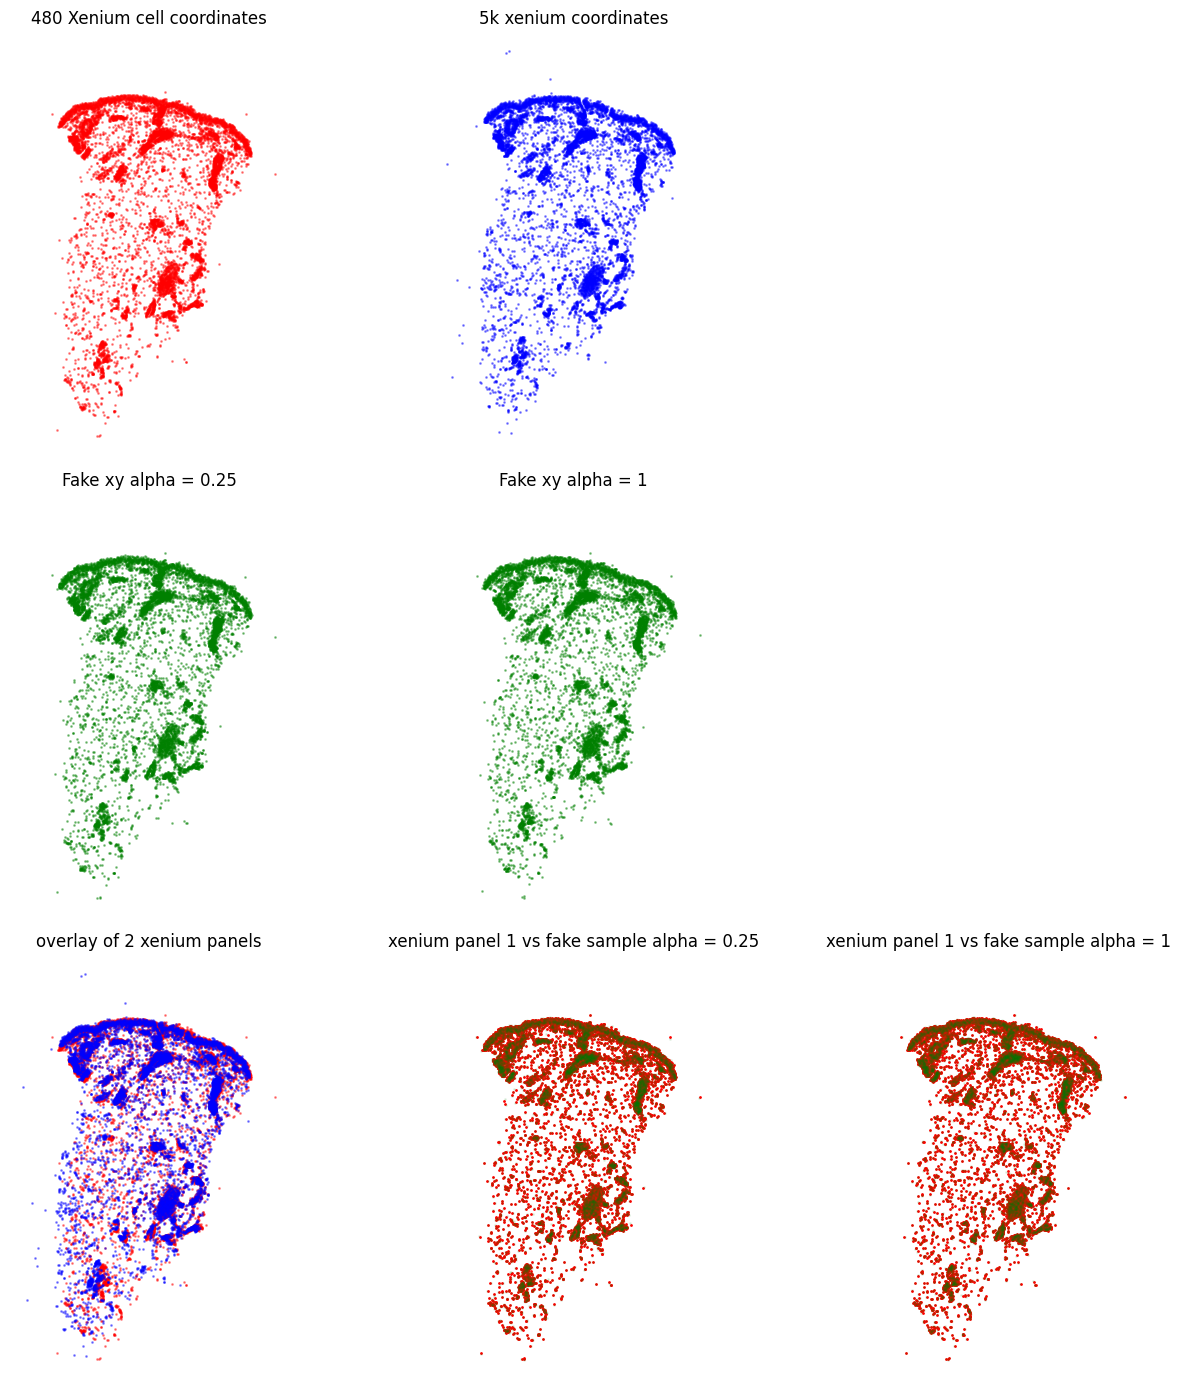

In [ ]:
from HINGE.evaluation import compute_population_diff_stats, create_synthetic_replicates
import matplotlib.pyplot as plt
from HINGE.utils import _xy
import numpy as np



stats = compute_population_diff_stats(
        adata_panel1   = adata_panel1,
        uni_panel1_normed     = uni_panel1_normed,
        adata_panel2   = adata_panel2,
        uni_panel2_normed     = uni_panel2_normed,
        overlap_genes  = overlap_genes,
        spatial_key_p1 =  "spatial",
        spatial_key_p2 = "spatial_registered",
    )

    # Step 2: replicates
fakes = create_synthetic_replicates(
        adata_panel1      = adata_panel1,
        uni_panel1_normed = uni_panel1_normed,
        stats             = stats,
        alpha_list        = [0.25,0.5,0.75,1],
        n_seeds_per_alpha = 1,
        noise_scale       = 1.0,
        spatial_key       =  "spatial",
        RECENTER          = False,
        xy_method="global_shift",
        xy_k=20,
        xy_local_noise_weight=0.25,
)



def plot_real_and_fake_samples(
    adata_panel1,
    adata_panel2,
    fakes,
    spatial_key_p1 = "spatial",
    spatial_key_p2 = "spatial_registered",
    n_sample       = 100000,
    s              = 1,
    save_path      = None,
):
    """
    Plot real panel1, real panel2, and all fake samples in a grid.

    Layout (for 4 fakes):
        Row 1: Real panel1  |  Real panel2  |  Overlay (p1 + p2)
        Row 2: fake alpha=0.25 | fake alpha=0.50 | Overlay (p1 + fake)
        Row 3: fake alpha=0.75 | fake alpha=1.00 | Overlay (p1 + fake)

    Parameters
    ----------
    adata_panel1 : AnnData   real panel1
    adata_panel2 : AnnData   real panel2 (registered)
    fakes        : list      output of create_synthetic_replicates()
                             (one per alpha when n_seeds_per_alpha=1)
    """
    xy_p1  = _xy(adata_panel1, spatial_key_p1)
    xy_p2  = _xy(adata_panel2, spatial_key_p2)

    rng     = np.random.default_rng(42)
    idx_p1  = rng.choice(len(xy_p1), min(n_sample, len(xy_p1)), replace=False)
    idx_p2  = rng.choice(len(xy_p2), min(n_sample, len(xy_p2)), replace=False)

    n_fakes = len(fakes)

    # Layout: first row = real samples, then 2 fakes per row
    n_fake_rows = int(np.ceil(n_fakes / 2))
    n_rows      = 1 + n_fake_rows
    n_cols      = 3   # individual p1 | individual p2/fake | overlay

    fig, axes = plt.subplots(n_rows, n_cols,
                              figsize=(n_cols * 6, n_rows * 5))
    fig.suptitle('Real Samples vs Synthetic Fake Samples\n'
                 '(cell spatial coordinates)',
                 fontsize=14, fontweight='bold')

    # ── Row 0: Real samples ───────────────────────────────────────
    axes[0, 0].scatter(*xy_p1[idx_p1].T, s=s, c='royalblue',
                        alpha=0.4, label='Panel1 (480)')
    axes[0, 0].set_title('Real Panel1 (480)', fontsize=11)

    axes[0, 1].scatter(*xy_p2[idx_p2].T, s=s, c='tomato',
                        alpha=0.4, label='Panel2 (5k, registered)')
    axes[0, 1].set_title('Real Panel2 (5k, registered)', fontsize=11)

    axes[0, 2].scatter(*xy_p1[idx_p1].T, s=s, c='royalblue',
                        alpha=0.4, label='Panel1')
    axes[0, 2].scatter(*xy_p2[idx_p2].T, s=s, c='tomato',
                        alpha=0.4, label='Panel2')
    axes[0, 2].set_title('Real Overlay (Panel1 + Panel2)', fontsize=11)
    axes[0, 2].legend(markerscale=6, fontsize=8)

    # ── Rows 1+: Fake samples ─────────────────────────────────────
    fake_colors = ['#2ecc71', '#f39c12', '#9b59b6', '#1abc9c',
                   '#e74c3c', '#3498db']

    for fake_idx, fake in enumerate(fakes):
        row  = 1 + fake_idx // 2
        col0 = (fake_idx % 2) * 1   # 0 or 1 → maps to col 0 or 1

        xy_f    = fake['xy']
        alpha_v = fake['alpha']
        rep     = fake['replicate']

        idx_f = rng.choice(len(xy_f), min(n_sample, len(xy_f)), replace=False)
        color = fake_colors[fake_idx % len(fake_colors)]

        # Individual fake plot (col 0 or 1)
        axes[row, col0].scatter(
            *xy_f[idx_f].T, s=s, c=color, alpha=0.4,
            label=f'Fake α={alpha_v:.2f}'
        )
        axes[row, col0].set_title(
            f'Fake (α={alpha_v:.2f}, rep={rep+1})', fontsize=11
        )

        # Overlay: panel1 + this fake (always col 2, but only for even fakes)
        if fake_idx % 2 == 0:
            axes[row, 2].scatter(
                *xy_p1[idx_p1].T, s=s, c='royalblue', alpha=0.3,
                label='Panel1 (real)'
            )
        axes[row, 2].scatter(
            *xy_f[idx_f].T, s=s, c=color, alpha=0.3,
            label=f'Fake α={alpha_v:.2f}'
        )
        axes[row, 2].set_title(
            f'Overlay: Panel1 + Fakes (row {row})', fontsize=11
        )
        axes[row, 2].legend(markerscale=6, fontsize=7)

    # ── Shared formatting ─────────────────────────────────────────
    for ax in axes.ravel():
        ax.set_aspect('equal')
        ax.axis('off')

    # Row labels
    row_labels = ['Real samples'] + \
                 [f'Fakes {i*2+1}-{min(i*2+2, n_fakes)}'
                  for i in range(n_fake_rows)]
    for row, label in enumerate(row_labels):
        axes[row, 0].set_ylabel(label, fontsize=10,
                                 fontweight='bold', labelpad=10)
        axes[row, 0].yaxis.set_visible(True)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=130, bbox_inches='tight')
        print(f"Saved: {save_path}")

    plt.show()
    
    
    
# ── Plot fake samples ─────────────────────────────────────────────
plot_real_and_fake_samples(
    adata_panel1 = adata_panel1,
    adata_panel2 = adata_panel2,
    fakes        = fakes,           # 4 fakes (one per alpha)
    save_path    = './hinge_step2_plots/real_vs_fake_coords.png'
)

# run test

In [60]:

df_results, fakes, stats = run_synthetic_evaluation(
    adata_panel1   = adata_panel1,
    uni_panel1_normed     = uni_panel1_normed,
    adata_panel2   = adata_panel2,
    uni_panel2_normed     = uni_panel2_normed,

    expr_panel1 =expr_480_list[0],
    expr_pca= expr_pca,
    overlap_genes= overlap_genes,
    
    xy_method="global_shift",

    N_PCA_MORPH = 256,
    
    SAMPLE_NAME       = "s1",
)

  Computing population-level difference statistics
  Panel1: 8978 cells  |  Panel2: 8899 cells

  Coordinate displacement field:
    median dx        = -0.68 um
    median dy        = -0.19 um
    median NN dist   = 22.87 um
    kept fraction    = 100.0%

  UNI (normalized space, 2048D):
    |delta_mean| median = 0.00264
    delta_std    median = 0.01713

  Expression (444 genes):
    |delta_mean| median = 0.0622
    delta_std    median = 0.1445
  Created s1_t: alpha=0.25  seed=0  xy_method=displacement_field  mean coord shift=12.96 um  n=8978
  Created s1_t: alpha=0.25  seed=1  xy_method=displacement_field  mean coord shift=12.97 um  n=8978
  Created s1_t: alpha=0.25  seed=2  xy_method=displacement_field  mean coord shift=12.89 um  n=8978
  Created s1_t: alpha=0.50  seed=3  xy_method=displacement_field  mean coord shift=21.29 um  n=8978
  Created s1_t: alpha=0.50  seed=4  xy_method=displacement_field  mean coord shift=21.43 um  n=8978
  Created s1_t: alpha=0.50  seed=5  xy_method=disp

In [ ]:
def estimate_max_dist(
    stats,
    coverage_target  = 0.90,   # fraction of true pairs to capture
    min_dist         = 15.0,   # absolute floor (um) — below this is too strict
    max_dist_cap     = 100.0,  # absolute ceiling (um) — above this is too lenient
    safety_factor    = 1.5,    # multiply estimated dist by this factor
    verbose          = True,
):
    """
    Automatically estimate max_dist for cell matching based on
    the empirical NN distance distribution between the two panels.

    Logic:
    ──────
    The stats dict contains xy_nn_dist: the distance from each panel1
    cell to its nearest panel2 neighbor (after registration).

    This distribution tells us:
        - If alignment is good  → NN distances are small → use small max_dist
        - If alignment is poor  → NN distances are large → use large max_dist

    We set max_dist = percentile(nn_dist, coverage_target * 100) * safety_factor

    This captures coverage_target fraction of true pairs while
    excluding cells with no plausible match nearby.

    Parameters
    ----------
    stats           : dict    output of compute_population_diff_stats()
    coverage_target : float   fraction of cells to include (default 0.90)
    min_dist        : float   floor on max_dist (um)
    max_dist_cap    : float   ceiling on max_dist (um)
    safety_factor   : float   multiplier — adds buffer above the percentile

    Returns
    -------
    max_dist        : float   recommended max_dist in um
    dist_stats      : dict    diagnostic statistics
    """
    nn_dist      = stats['xy_nn_dist']
    keep_mask    = stats['xy_keep_mask']
    nn_dist_used = nn_dist[keep_mask]

    # Percentiles of the NN distance distribution
    p50  = float(np.percentile(nn_dist_used, 50))
    p75  = float(np.percentile(nn_dist_used, 75))
    p90  = float(np.percentile(nn_dist_used, 90))
    p95  = float(np.percentile(nn_dist_used, 95))
    p99  = float(np.percentile(nn_dist_used, 99))

    # Base estimate: percentile at coverage_target
    pct_for_target = float(np.percentile(nn_dist_used,
                                          coverage_target * 100))

    # Apply safety factor and clamp
    max_dist = float(np.clip(
        pct_for_target * safety_factor,
        min_dist,
        max_dist_cap
    ))

    # Alignment quality label
    if p50 < 10:
        quality = "excellent  (p50 < 10 um)"
    elif p50 < 20:
        quality = "good       (p50 < 20 um)"
    elif p50 < 40:
        quality = "moderate   (p50 < 40 um)"
    else:
        quality = "poor       (p50 >= 40 um)"

    dist_stats = {
        'p50'             : p50,
        'p75'             : p75,
        'p90'             : p90,
        'p95'             : p95,
        'p99'             : p99,
        'pct_for_target'  : pct_for_target,
        'coverage_target' : coverage_target,
        'safety_factor'   : safety_factor,
        'max_dist'        : max_dist,
        'alignment_quality': quality,
    }

    if verbose:
        print("\n" + "=" * 55)
        print("  Auto max_dist estimation")
        print("=" * 55)
        print(f"  Alignment quality : {quality}")
        print(f"  NN dist p50       : {p50:.2f} um")
        print(f"  NN dist p75       : {p75:.2f} um")
        print(f"  NN dist p90       : {p90:.2f} um")
        print(f"  NN dist p95       : {p95:.2f} um")
        print(f"  NN dist p99       : {p99:.2f} um")
        print(f"  Coverage target   : {coverage_target:.0%}")
        print(f"  Percentile at target: {pct_for_target:.2f} um")
        print(f"  Safety factor     : {safety_factor:.1f}x")
        print(f"  → Recommended max_dist = {max_dist:.1f} um")
        print(f"    (clamped to [{min_dist}, {max_dist_cap}] um)")

    return max_dist, dist_stats


def plot_nn_dist_distribution(stats, max_dist_auto, save_path=None):
    """
    Plot the NN distance distribution with the auto max_dist marked.
    Useful for validating the estimate visually.
    """
    nn_dist = stats['xy_nn_dist']
    keep    = stats['xy_keep_mask']

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle('NN Distance Distribution — Alignment Quality Check',
                 fontsize=12, fontweight='bold')

    # ── Histogram ─────────────────────────────────────────────────
    ax = axes[0]
    ax.hist(nn_dist[keep], bins=100, color='steelblue',
             alpha=0.8, edgecolor='none', label='NN dist (kept pairs)')
    ax.axvline(max_dist_auto, color='red', linestyle='--', linewidth=2,
               label=f'auto max_dist = {max_dist_auto:.1f} um')
    ax.axvline(np.median(nn_dist[keep]), color='orange', linestyle=':',
               linewidth=1.5,
               label=f'median = {np.median(nn_dist[keep]):.1f} um')
    ax.set_xlabel('NN distance (um)')
    ax.set_ylabel('Count')
    ax.set_title('Full distribution')
    ax.legend(fontsize=9)

    # ── CDF ───────────────────────────────────────────────────────
    ax  = axes[1]
    d   = np.sort(nn_dist[keep])
    cdf = np.arange(1, len(d) + 1) / len(d)
    ax.plot(d, cdf, color='steelblue', linewidth=2)
    ax.axvline(max_dist_auto, color='red', linestyle='--', linewidth=2,
               label=f'auto max_dist = {max_dist_auto:.1f} um')
    ax.axhline(0.90, color='gray', linestyle=':', alpha=0.6,
               label='90% coverage')

    # Annotate coverage at auto max_dist
    coverage_at_auto = float((nn_dist[keep] <= max_dist_auto).mean())
    ax.scatter([max_dist_auto], [coverage_at_auto],
               color='red', zorder=5, s=60)
    ax.text(max_dist_auto + 1, coverage_at_auto - 0.04,
            f'{coverage_at_auto:.1%}',
            color='red', fontsize=9)

    ax.set_xlabel('NN distance (um)')
    ax.set_ylabel('Cumulative fraction')
    ax.set_title('CDF — coverage at max_dist')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=130, bbox_inches='tight')
        print(f"Saved: {save_path}")
    plt.show()

In [ ]:
max_dist_auto, dist_stats = estimate_max_dist(
    stats           = stats,
    coverage_target = 0.90,
    safety_factor   = 1.5,
    min_dist        = 15.0,
    max_dist_cap    = 100.0,
)

plot_nn_dist_distribution(
    stats         = stats,
    max_dist_auto = max_dist_auto,
    save_path     = './hinge_step2_plots/nn_dist_distribution.png'
)

print(f"\nUsing max_dist = {max_dist_auto:.1f} um for matching")